# Palier 2 · Le perceptron multicouche (MLP)

## 1. Imports, graine et données

In [1]:
# À mettre AVANT d'importer TensorFlow : désactive les optimisations oneDNN,
# qui changent l'ordre des calculs et donnent des résultats un peu différents à chaque lancement
import os
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

SEED = 42
keras.utils.set_random_seed(SEED)

print("Python    :", sys.version.split()[0])
print("NumPy     :", np.__version__)
print("TensorFlow:", tf.__version__)
print("Keras     :", keras.__version__)

Python    : 3.12.7
NumPy     : 2.5.5
TensorFlow: 2.21.0
Keras     : 3.15.1


In [2]:
# Les mêmes jeux que dans le notebook 1 (même découpage, même graine)
sys.path.append("..")
from src.data import load_data

x_train, y_train, x_val, y_val, x_test, y_test = load_data(seed=SEED)

# Un MLP prend un vecteur en entrée : 28 x 28 -> 784
X_train = x_train.reshape(len(x_train), 784)
X_val = x_val.reshape(len(x_val), 784)
X_test = x_test.reshape(len(x_test), 784)  # gardé pour la section 9 seulement

print("X_train :", X_train.shape, "/ X_val :", X_val.shape, "/ X_test :", X_test.shape)
print("Pixels entre", X_train.min(), "et", X_train.max())

X_train : (54000, 784) / X_val : (6000, 784) / X_test : (10000, 784)
Pixels entre 0.0 et 1.0


J'utilise les mêmes jeux que dans le notebook 1 : 54 000 images pour l'entraînement et 6 000 pour la validation, avec les pixels entre 0 et 1. J'aplatis chaque image en un vecteur de 784 pixels, parce qu'une couche `Dense` ne sait pas lire une image 2D. Je prépare aussi `X_test`, mais il ne servira qu'une seule fois, à la section 9.

*Reproductibilité :* en plus de la graine, je désactive oneDNN (`TF_ENABLE_ONEDNN_OPTS=0`, avant d'importer TensorFlow), et `run()` active `enable_op_determinism()`. Sans ça, j'obtenais 2,02 %, puis 2,10 %, puis 2,13 % d'erreur en relançant exactement le même code. Maintenant, deux relances donnent les mêmes chiffres au centième près (seule la durée varie).

## 2. Fonctions utiles : plot_history et run

J'ai mis les fonctions dans `src/utils.py` pour pouvoir les réutiliser dans le notebook du CNN :

- `build_mlp(hidden, dropout, batchnorm)` construit un MLP : entrée de 784 pixels → couches cachées ReLU → 10 sorties softmax ;
- `plot_history(history, titre)` trace la loss et l'erreur (1 − accuracy), pour l'entraînement et pour la validation, côte à côte ;
- `run(...)` fait un essai complet. Elle fixe la graine, **construit un modèle neuf**, compile, chronomètre l'entraînement, trace les courbes et ajoute une ligne au tableau `resultats`.

`run` reçoit une **fonction** qui crée le modèle (`lambda: build_mlp(...)`), et pas un modèle déjà construit. Comme ça, la graine est fixée *avant* l'initialisation des poids : chaque essai part des mêmes poids, et je ne continue jamais par erreur l'entraînement d'un ancien modèle.

In [3]:
from src.utils import build_mlp, plot_history, run

donnees = (X_train, y_train, X_val, y_val)   # jamais le test pendant les essais
resultats = []                               # une ligne par essai, affichée en tableau à la section 8

## 3. MLP de référence

In [4]:
# On construit une fois le modèle juste pour lire son résumé
keras.utils.set_random_seed(SEED)
build_mlp(hidden=(256,)).summary()

Model: "mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 203,530 (795.04 KB)

 Trainable params: 203,530 (795.04 KB)

 Non-trainable params: 0 (0.00 B)

**Calcul du nombre de paramètres à la main** (un poids par connexion, plus un biais par neurone) :

| couche | calcul | paramètres |
|---|---|---|
| Dense 784 → 256 | 784 × 256 + 256 | 200 960 |
| Dense 256 → 10 | 256 × 10 + 10 | 2 570 |
| **total** | | **203 530** |

C'est exactement ce qu'affiche `summary()` (203 530). Presque tout est dans la première couche (99 %), parce que chaque pixel est relié à chacun des 256 neurones.

Epoch 1/20


422/422 - 2s - 5ms/step - accuracy: 0.9117 - loss: 0.3142 - val_accuracy: 0.9505 - val_loss: 0.1809


Epoch 2/20


422/422 - 1s - 2ms/step - accuracy: 0.9611 - loss: 0.1357 - val_accuracy: 0.9650 - val_loss: 0.1315


Epoch 3/20


422/422 - 1s - 2ms/step - accuracy: 0.9733 - loss: 0.0936 - val_accuracy: 0.9697 - val_loss: 0.1101


... (30 outputs left out)

Epoch 19/20


422/422 - 1s - 3ms/step - accuracy: 0.9993 - loss: 0.0038 - val_accuracy: 0.9808 - val_loss: 0.0991


Epoch 20/20


422/422 - 1s - 3ms/step - accuracy: 0.9997 - loss: 0.0024 - val_accuracy: 0.9797 - val_loss: 0.1016


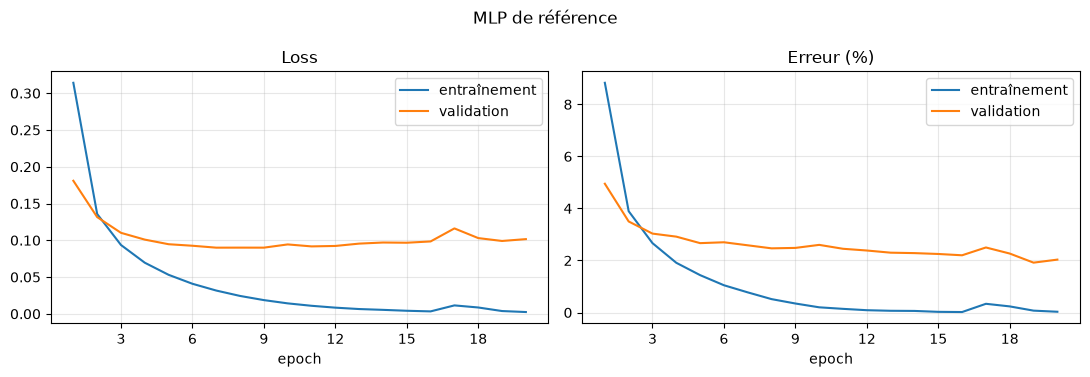

In [5]:
# Référence : 784 -> 256 (ReLU) -> 10 (softmax), Adam lr = 0,001, batch 128, 20 epochs
model_ref, hist_ref = run(
    "MLP de référence",
    creer_modele=lambda: build_mlp(hidden=(256,)),
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    donnees=donnees,
    resultats=resultats,
    batch_size=128,
    epochs=20,
    changement="référence : 256 neurones, Adam 1e-3, batch 128",
    save="../images/p2_ref_courbes.png",
)

In [6]:
pd.DataFrame(resultats)

,nom,changement,parametres,epochs,erreur_val_%,meilleure_erreur_val_%,epoch_meilleure,duree_s
0,MLP de référence,"référence : 256 neurones, Adam 1e-3, batch 128",203530,20,2.03,1.92,19,24.7


**Pourquoi 422 itérations par epoch ?** Une itération, c'est un paquet (batch) de 128 images : le modèle calcule l'erreur sur ce paquet, puis corrige ses poids une fois. Pour voir les 54 000 images une fois (= une epoch), il faut 54 000 / 128 = 421,875 paquets. On fait donc 421 paquets complets, plus un dernier paquet de 54 000 − 421 × 128 = **112 images**, soit **422 itérations**. C'est bien le `422/422` affiché par Keras à chaque epoch.

**Ce que je lis sur les courbes** (`images/p2_ref_courbes.png`) :

- L'erreur de **validation** baisse vite : 4,95 % après la 1re epoch, environ 2,6 % à l'epoch 7. Ensuite, elle descend lentement : **1,92 % au mieux (epoch 19)** et **2,03 % à la fin (epoch 20)**.
- Pendant ce temps, l'erreur d'**entraînement** tombe presque à 0 % (accuracy de 99,97 %) : le modèle a quasiment appris les 54 000 images par cœur.
- La **loss de validation** est au plus bas entre les epochs 7 et 9 (0,090), puis elle remonte (0,102 à la fin), alors que la loss d'entraînement continue de baisser. **C'est un début de surapprentissage** : le modèle devient trop sûr de lui sur les images de validation qu'il classe mal, même si le nombre d'erreurs ne remonte pas encore. L'écart entre train et validation s'agrandit. Je traiterai ça à la section 6 (dropout, early stopping).
- Il y a un pic à l'epoch 17 : la loss d'entraînement remonte d'un coup (de 0,003 à 0,011), et l'erreur de validation aussi. C'est un « à-coup » d'Adam quand la loss est déjà presque nulle, et il se corrige dès les epochs suivantes.
- L'entraînement prend environ 30 s sur le CPU (environ 1,5 s par epoch).

**Comparaison avec la baseline :** le MLP de référence fait **2,03 %** d'erreur sur la validation à la fin (1,92 % au mieux), contre **3,42 %** pour la forêt aléatoire du notebook 1. La baseline est battue ✅ (environ 40 % d'erreurs en moins).

## 4. Comparaison de configurations (une variable à la fois)

## 5. Learning rate trop bas / trop élevé

## 6. Surapprentissage et sa correction

## 7. Batch normalization : avec et sans

## 8. Tableau récapitulatif et choix du meilleur modèle (sur la validation)

## 9. Évaluation finale sur le test (une seule fois)

## 10. Réponses aux questions d'explication

## 11. Bilan du palier 2